In [ ]:
import re
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from config import SAMPLE_NUM

CLASSIFICATION_PATH = Path("classification_results")
IMPUTATION_PATH = Path("imputation_reports")
PLOT_PATH = Path("plots")
PLOT_PATH.mkdir(exist_ok=True)

def parse_classification_result_filename(filename):
    name = filename.replace('.txt', '')
    
    match = re.match(r'^(.+?)_(mar|mcar|mnar|none)(\d+)_([^_]+)_([^_]+)$', name)
    
    if not match:
        return None
    
    disease = match.group(1)
    missing_type = match.group(2)
    missing_pct = int(match.group(3))
    imputation_method = match.group(4)
    classification_method = match.group(5)
    return {
        'disease': disease,
        'missing_type': missing_type,
        'missing_pct': missing_pct,
        'imputation': imputation_method,
        'classification': classification_method
    }

def parse_imputation_report_filename(filename):
    name = filename.replace('.txt', '').replace('_report', '')
    
    match = re.match(r'^(.+?)_train_(mar|mcar|mnar)(\d+)_([^_]+)$', name)
    
    if not match:
        return None
    
    disease = match.group(1)
    missing_type = match.group(2)
    missing_pct = int(match.group(3))
    imputation_method = match.group(4)
    return {
        'disease': disease,
        'missing_type': missing_type,
        'missing_pct': missing_pct,
        'imputation': imputation_method
    }

def extract_metrics_from_classification_result(file_path):
    avg_acc = None
    sd_acc = None
    avg_f1 = None
    sd_f1 = None
    avg_auc = None
    sd_auc = None
    try:
        with open(file_path, 'r') as f:
            for line in f:
                if line.startswith('Accuracy:'):
                    avg_acc = float(line.split('Accuracy:')[1].strip())
                if line.startswith('Accuracy std:'):
                    sd_acc = float(line.split('Accuracy std:')[1].strip())
                if line.startswith('F1 Score:'):
                    avg_f1 = float(line.split('F1 Score:')[1].strip())
                if line.startswith('F1 Score std:'):
                    sd_f1 = float(line.split('F1 Score std:')[1].strip())
                if line.startswith('AUC:'):
                    avg_auc = float(line.split('AUC:')[1].strip())
                if line.startswith('AUC std:'):
                    sd_auc = float(line.split('AUC std:')[1].strip())
        return avg_acc, sd_acc, avg_f1, sd_f1, avg_auc, sd_auc
    except Exception as e:
        print(f"Error reading file {file_path}: {e}")
        return None, None, None, None, None, None

def extract_metrics_from_imputation_report(file_path):
    cells_total = None
    time_total = None
    time_per_cell = None
    try:
        with open(file_path, 'r') as f:
            for line in f:
                if line.startswith('Missing cells:'):
                    match = re.search(r'Missing cells:\s*([\d.]+)', line)
                    if match:
                        cells_total = float(match.group(1))
                if line.startswith('Elapsed time:'):
                    match = re.search(r'Elapsed time:\s*([\d.]+)', line)
                    if match:
                        time_total = float(match.group(1))
                if line.startswith('Average time per cell:'):
                    match = re.search(r'Average time per cell:\s*([\d.]+)', line)
                    if match:
                        time_per_cell = float(match.group(1))
        return cells_total, time_total, time_per_cell
    except Exception as e:
        print(f"Error extracting time from file {file_path}: {e}")
        return None, None

In [ ]:
class_results = []

for file_path in sorted(CLASSIFICATION_PATH.glob("*.txt")):
    parsed = parse_classification_result_filename(file_path.name)
    if parsed:
        accuracy, sd_acc, f1, sd_f1, auc, sd_auc = extract_metrics_from_classification_result(file_path)
        parsed['accuracy'] = accuracy
        parsed['sd_accuracy'] = sd_acc
        parsed['f1'] = f1
        parsed['sd_f1'] = sd_f1
        parsed['auc'] = auc
        parsed['sd_auc'] = sd_auc
        class_results.append(parsed)

df_class = pd.DataFrame(class_results)

diseases = df_class['disease'].unique()
disease_dataframes = {}

for disease in sorted(diseases):
    df_disease = df_class[df_class['disease'] == disease][['missing_pct', 'missing_type', 'imputation', 'classification', 'accuracy', 'sd_accuracy', 'f1', 'sd_f1', 'auc', 'sd_auc']].sort_values(['missing_pct', 'imputation', 'classification'])
    disease_dataframes[disease] = df_disease
    print(f"Dataset: {disease}")
    print(df_disease.reset_index(drop=True))
    print()

Dataset: NF1
     missing_pct missing_type  imputation      classification  accuracy  \
0              0         none        none  logisticRegression  0.500000   
1              0         none        none        randomForest  0.500000   
2              0         none        none                 svm  0.500000   
3              0         none        none             xgboost  0.442308   
4             10          mar         knn  logisticRegression  0.534615   
..           ...          ...         ...                 ...       ...   
647           90         mcar  regression                 svm  0.526923   
648           90         mnar  regression                 svm  0.519231   
649           90          mar  regression             xgboost  0.480769   
650           90         mcar  regression             xgboost  0.546154   
651           90         mnar  regression             xgboost  0.530769   

     sd_accuracy        f1     sd_f1       auc    sd_auc  
0       0.000000  0.380952 

***Detailed graphs***

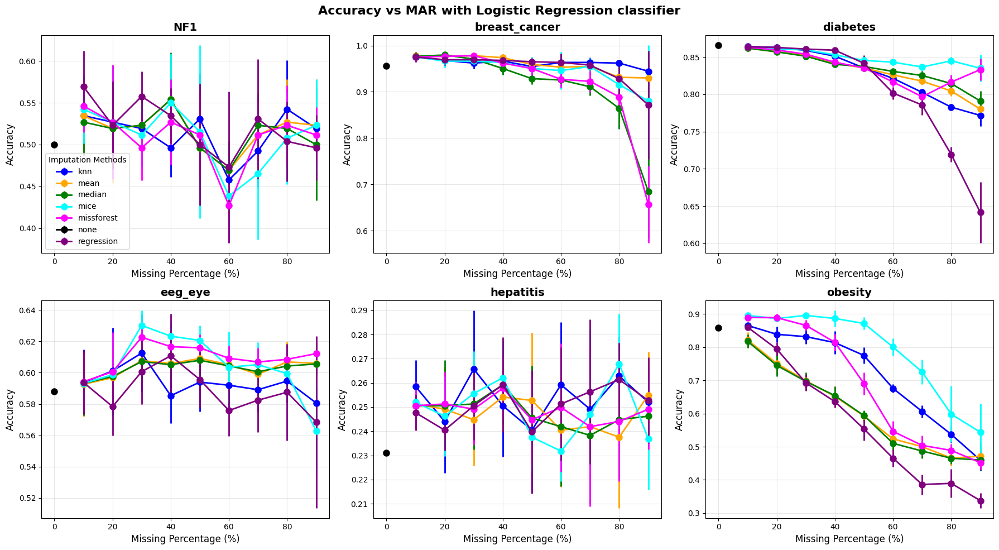

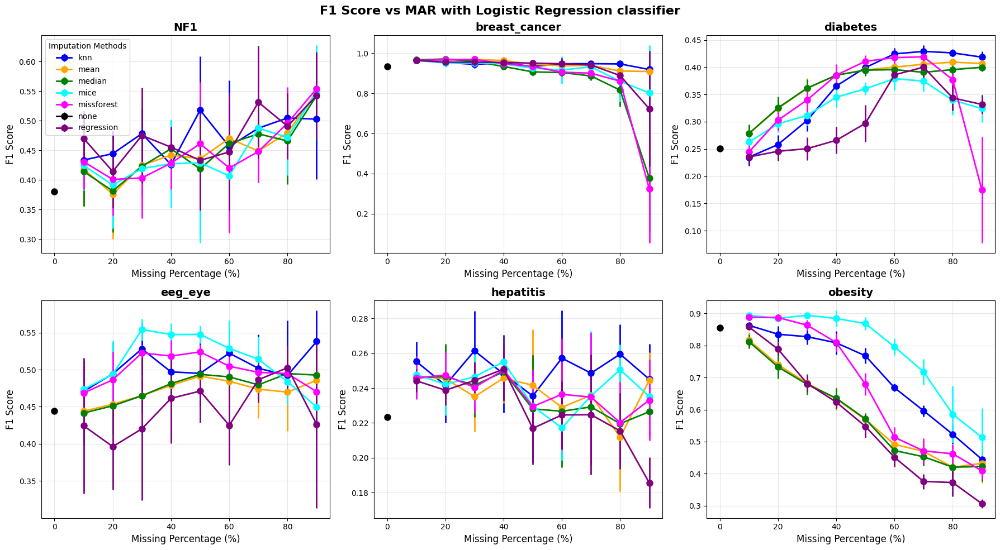

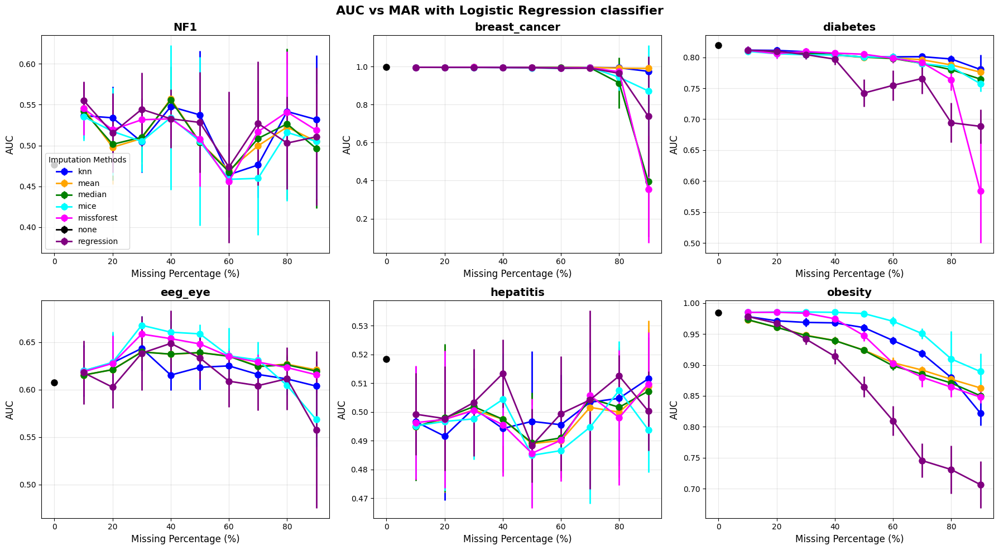

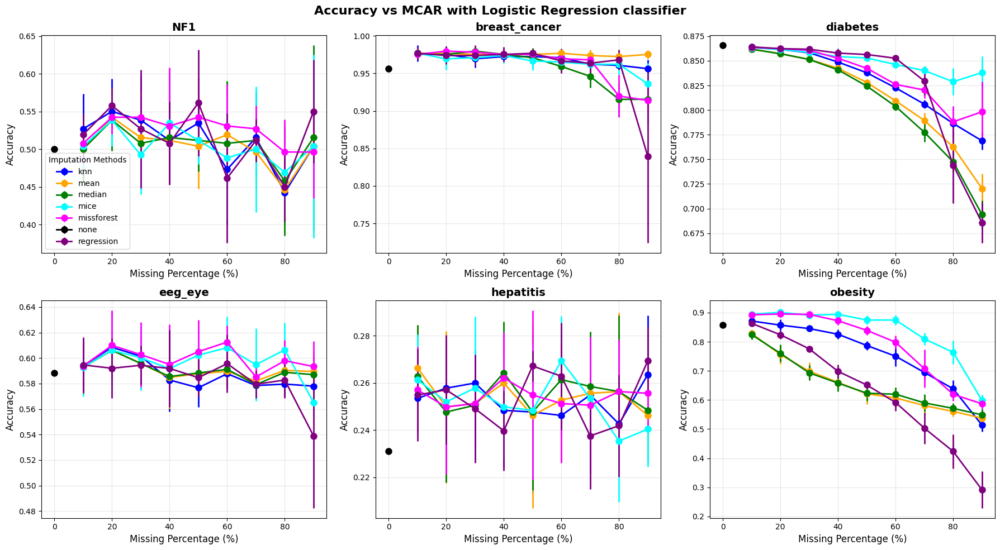

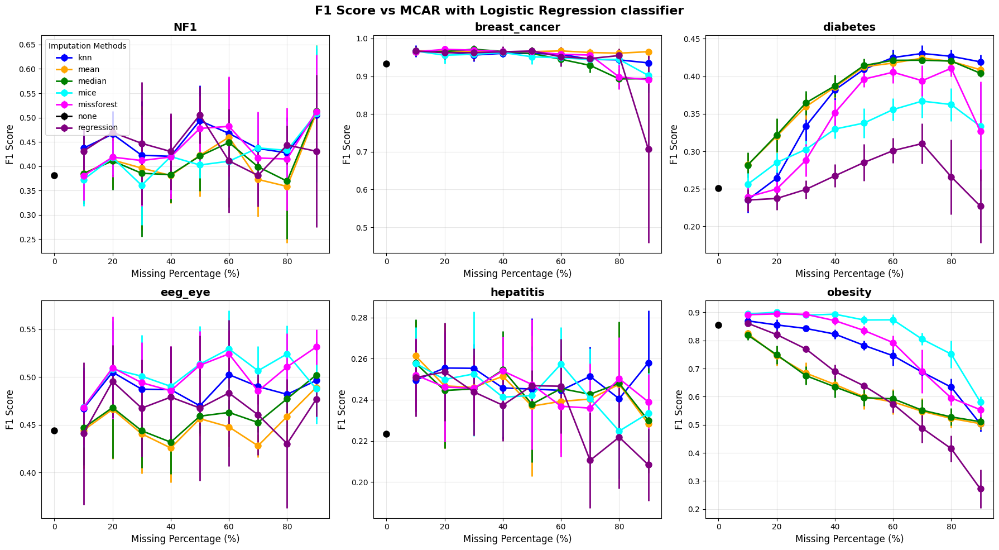

...

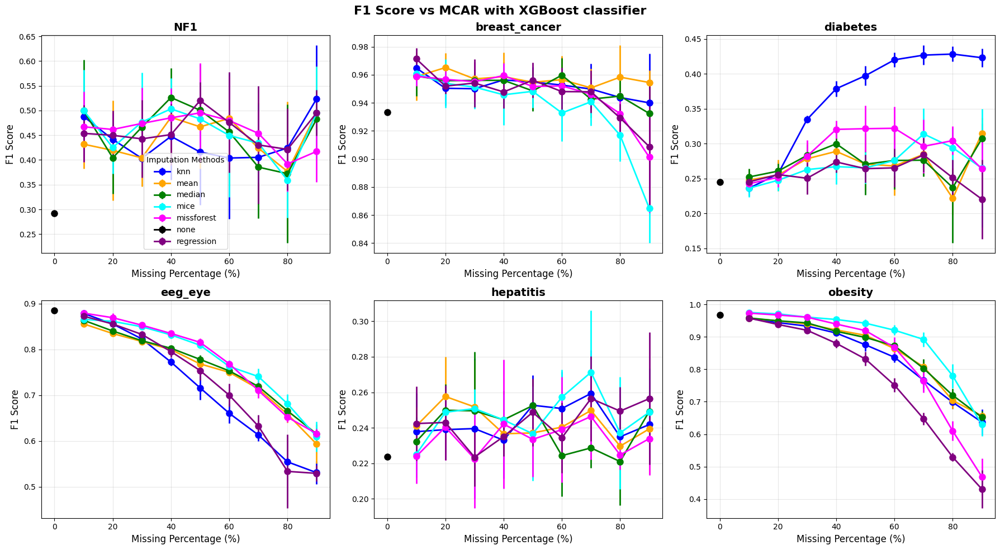

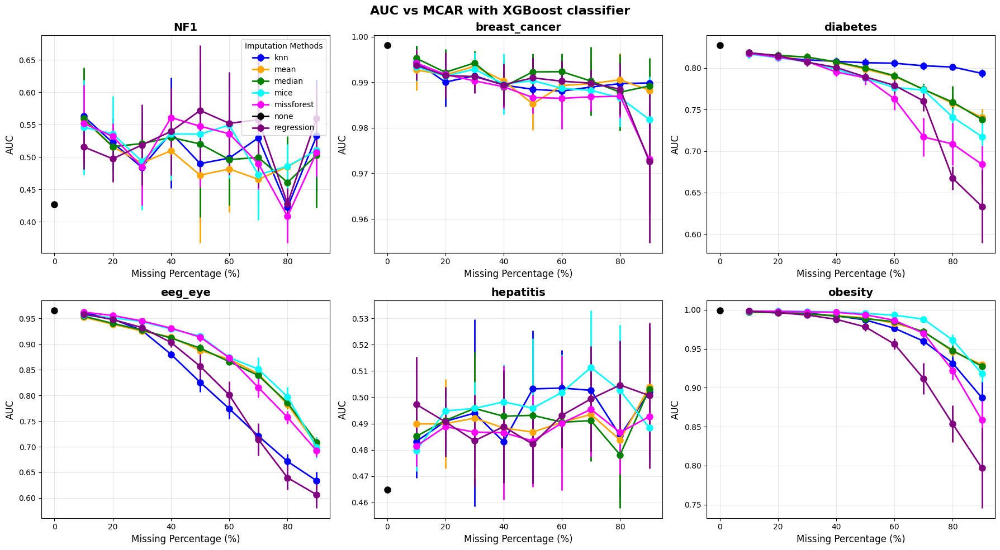

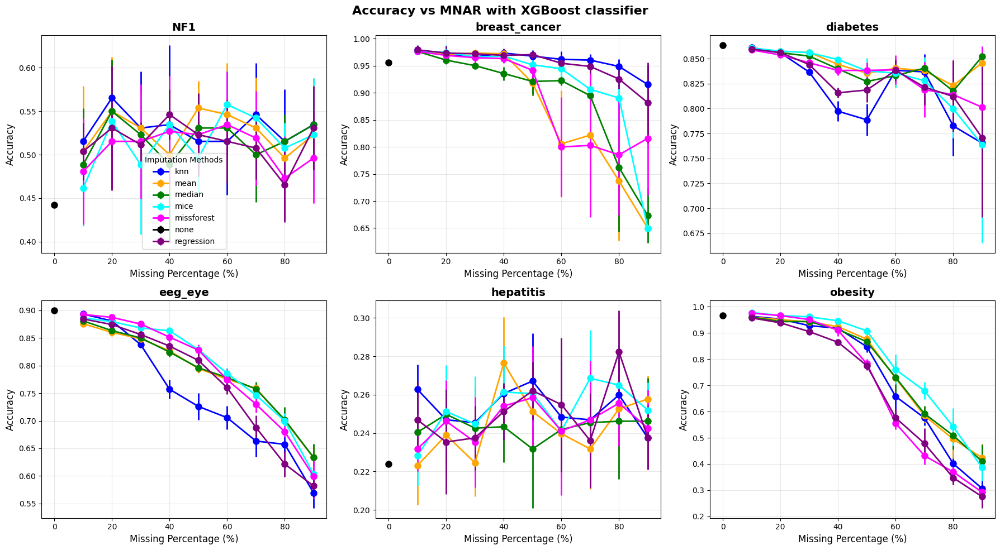

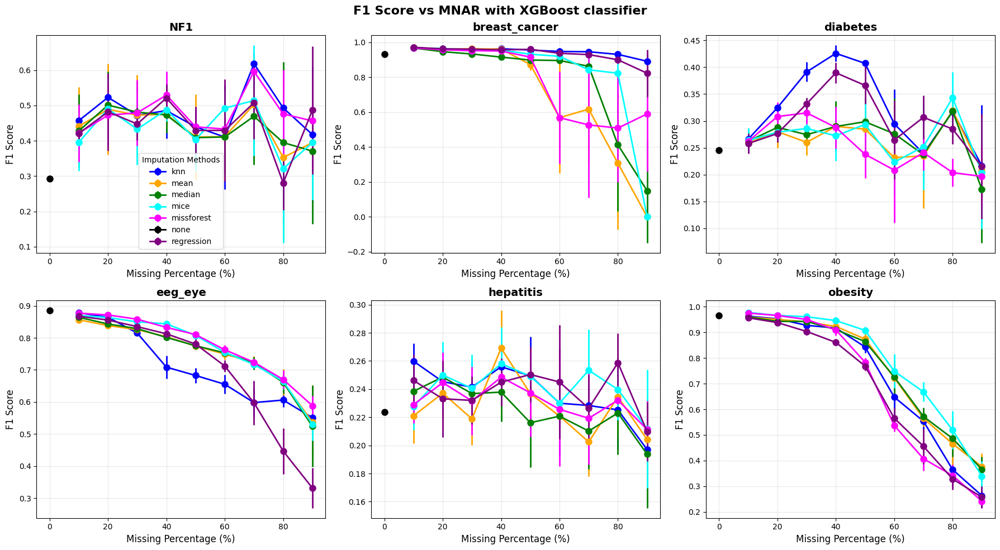

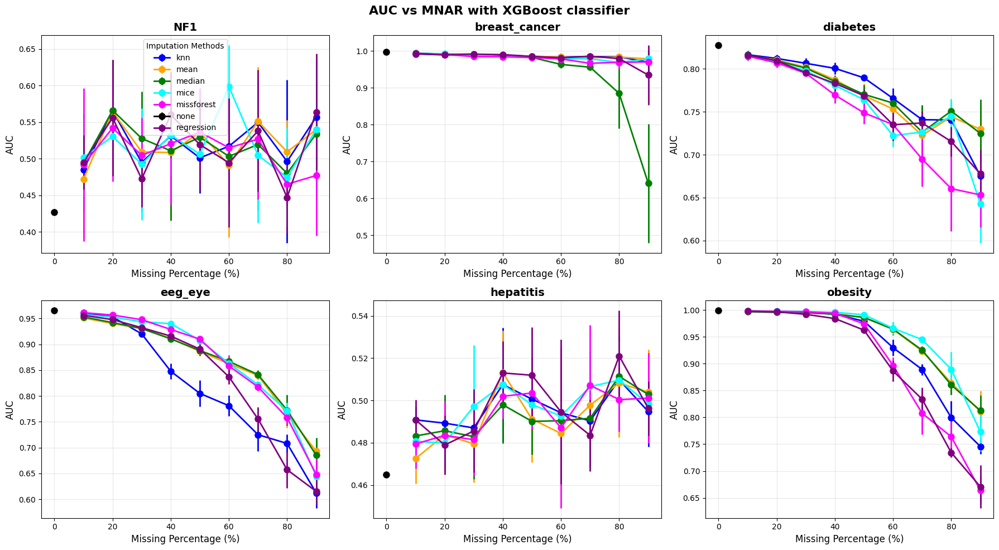

In [3]:
colors = {
    'knn': 'blue',
    'mean': 'orange',
    'median': 'green',
    'regression': 'purple',
    "mice": 'cyan',
    "missforest": 'magenta',
    "none": 'black'
}

metrics = {
    'accuracy': 'Accuracy',
    'f1': 'F1 Score',
    'auc': 'AUC'
}

classificators = {
    'logisticRegression': 'Logistic Regression',
    'randomForest': 'Random Forest',
    'svm': 'SVM',
    'xgboost': 'XGBoost'
}

missing_types = {
    'mar': 'MAR',
    'mcar': 'MCAR',
    'mnar': 'MNAR'
}

diseases = sorted(disease_dataframes.keys())

for class_key, class_name in classificators.items():
    for miss_type_key, miss_type_name in missing_types.items():
        for metric_key, metric_name in metrics.items():
            fig, axes = plt.subplots(2, 3, figsize=(18, 10))
            fig.suptitle(f'{metric_name} vs {miss_type_name} with {class_name} classifier', fontsize=16, fontweight='bold')
            axes = axes.flatten()

            for idx, (disease, df) in enumerate(disease_dataframes.items()):
                ax = axes[idx]
                
                imputation_methods = sorted(df['imputation'].unique())
                
                for method in imputation_methods:
                    method_data = df[
                        (df['imputation'] == method) &
                        (df['classification'] == class_key) &
                        ((df['missing_type'] == miss_type_key) | (df['missing_type'] == 'none') )].sort_values('missing_pct')
                    ax.errorbar(method_data['missing_pct'], method_data[metric_key], yerr=method_data[f'sd_{metric_key}'],
                            marker='o', label=method, color=colors.get(method, None), linewidth=2, markersize=8)
                
                ax.set_xlabel('Missing Percentage (%)', fontsize=12)
                ax.set_ylabel(metric_name, fontsize=12)
                ax.set_title(disease, fontsize=14, fontweight='bold')
                ax.grid(True, alpha=0.3)
                
                if idx == 0:
                    ax.legend(title='Imputation Methods', fontsize=10)

            plt.tight_layout()

            out_dir_path = PLOT_PATH / f"Metrics/{miss_type_name}/{metric_name}"
            out_dir_path.mkdir(parents=True, exist_ok=True)
            out_file_path = out_dir_path / f"{class_name}.png"
            plt.savefig(out_file_path)
            
            plt.show()

***Imputation method - Missing % - AUC drop for MAR***

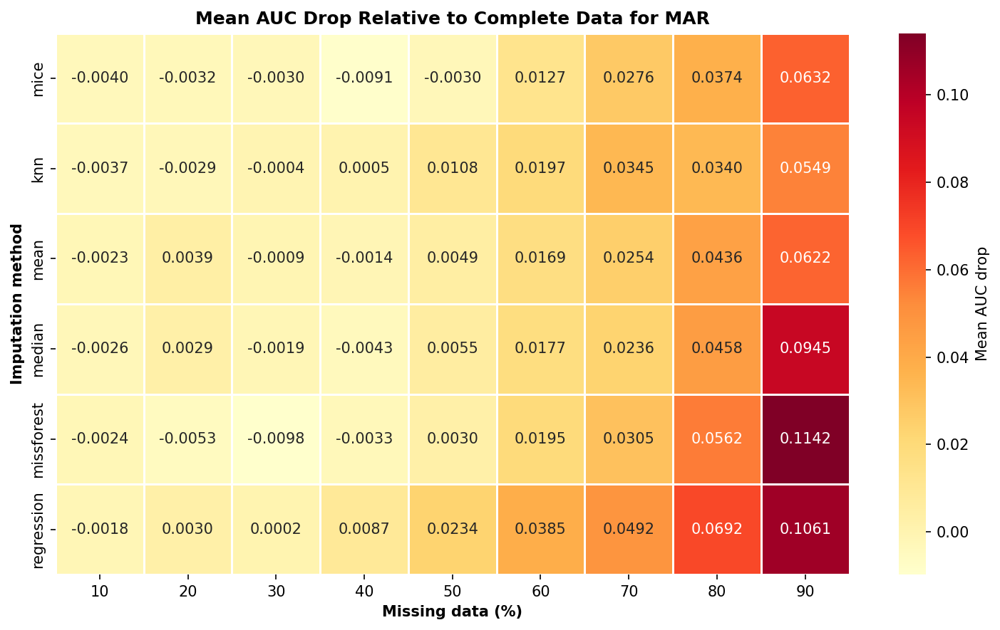

In [4]:
auc_processed_dfs_mar = []

for dataset_name, df in disease_dataframes.items():
    baseline = df[df['missing_pct'] == 0][['classification', 'auc']].copy()
    baseline.rename(columns={'auc': 'baseline_auc'}, inplace=True)
    
    df_merged = df.merge(baseline, on='classification', how='left')
    df_merged['auc_drop'] = df_merged['baseline_auc'] - df_merged['auc']
    df_merged['dataset'] = dataset_name
    
    auc_processed_dfs_mar.append(df_merged)

full_auc_df = pd.concat(auc_processed_dfs_mar, ignore_index=True)

df_auc_imputed_only_mar = full_auc_df[(full_auc_df['missing_pct'] > 0) & (full_auc_df['missing_type'] == 'mar')]

pivot_mpc = df_auc_imputed_only_mar.pivot_table(
    values='auc_drop', 
    index='imputation', 
    columns='missing_pct', 
    aggfunc='mean'
)
pivot_mpc = pivot_mpc.loc[pivot_mpc.mean(axis=1).sort_values().index]

plt.figure(figsize=(10, 6), dpi=150)
sns.heatmap(
    pivot_mpc, 
    annot=True, 
    fmt=".4f", 
    cmap="YlOrRd",
    cbar_kws={'label': 'Mean AUC drop'},
    linewidths=0.5
)

plt.title(
    'Mean AUC Drop Relative to Complete Data for MAR', 
    fontweight='bold'
    )
plt.xlabel('Missing data (%)', fontweight='bold')
plt.ylabel('Imputation method', fontweight='bold')
plt.tight_layout()

out_dir_path = PLOT_PATH
out_dir_path.mkdir(parents=True, exist_ok=True)
out_file_path = out_dir_path / f"AUCdrop_ImpMethod_MissPrct_MAR.png"
plt.savefig(out_file_path)
            
plt.show()

***Imputation method - Missing % - AUC drop for MCAR***

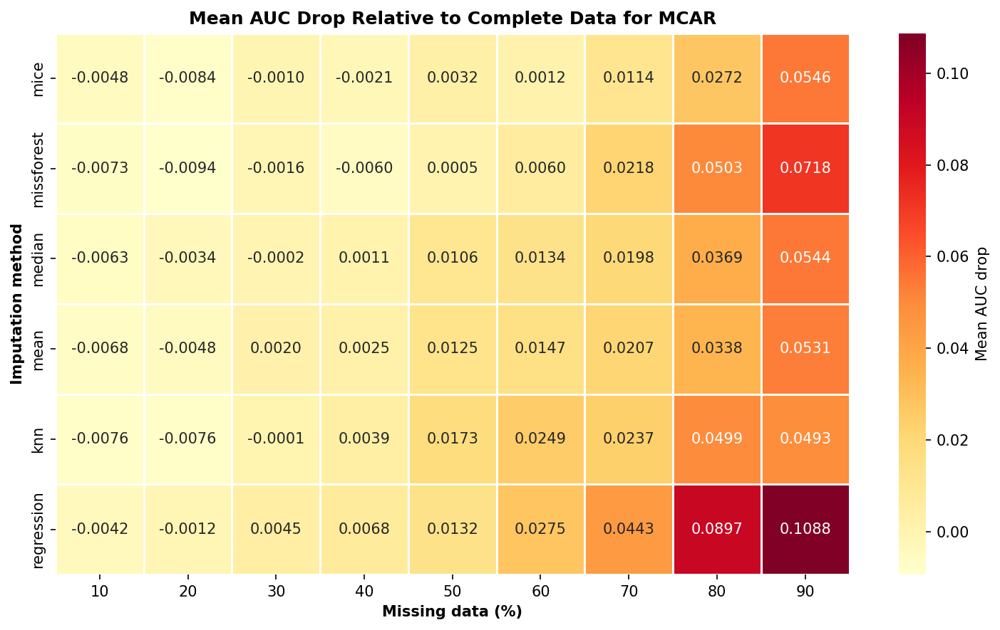

In [5]:
auc_processed_dfs_mcar = []

for dataset_name, df in disease_dataframes.items():
    baseline = df[df['missing_pct'] == 0][['classification', 'auc']].copy()
    baseline.rename(columns={'auc': 'baseline_auc'}, inplace=True)
    
    df_merged = df.merge(baseline, on='classification', how='left')
    df_merged['auc_drop'] = df_merged['baseline_auc'] - df_merged['auc']
    df_merged['dataset'] = dataset_name
    
    auc_processed_dfs_mcar.append(df_merged)

full_auc_df = pd.concat(auc_processed_dfs_mcar, ignore_index=True)

df_auc_imputed_only_mcar = full_auc_df[(full_auc_df['missing_pct'] > 0) & (full_auc_df['missing_type'] == 'mcar')]

pivot_mpc = df_auc_imputed_only_mcar.pivot_table(
    values='auc_drop', 
    index='imputation', 
    columns='missing_pct', 
    aggfunc='mean'
)
pivot_mpc = pivot_mpc.loc[pivot_mpc.mean(axis=1).sort_values().index]

plt.figure(figsize=(10, 6), dpi=150)
sns.heatmap(
    pivot_mpc, 
    annot=True, 
    fmt=".4f", 
    cmap="YlOrRd",
    cbar_kws={'label': 'Mean AUC drop'},
    linewidths=0.5
)

plt.title(
    'Mean AUC Drop Relative to Complete Data for MCAR', 
    fontweight='bold'
    )
plt.xlabel('Missing data (%)', fontweight='bold')
plt.ylabel('Imputation method', fontweight='bold')
plt.tight_layout()

out_dir_path = PLOT_PATH
out_dir_path.mkdir(parents=True, exist_ok=True)
out_file_path = out_dir_path / f"AUCdrop_ImpMethod_MissPrct_MCAR.png"
plt.savefig(out_file_path)
            
plt.show()

***Imputation method - Missing % - AUC drop for MNAR***

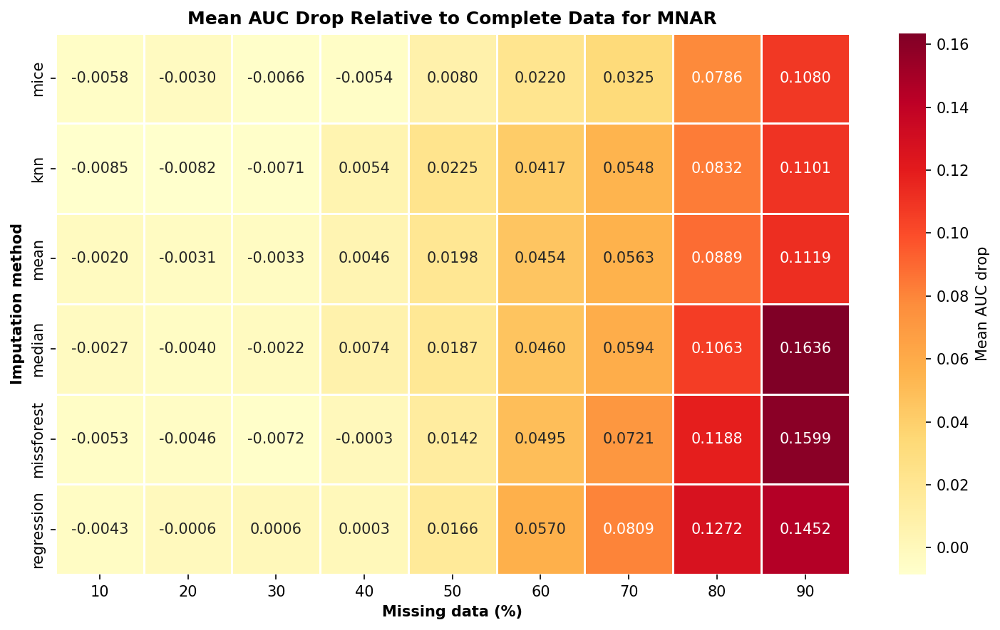

In [6]:
auc_processed_dfs_mnar = []

for dataset_name, df in disease_dataframes.items():
    baseline = df[df['missing_pct'] == 0][['classification', 'auc']].copy()
    baseline.rename(columns={'auc': 'baseline_auc'}, inplace=True)
    
    df_merged = df.merge(baseline, on='classification', how='left')
    df_merged['auc_drop'] = df_merged['baseline_auc'] - df_merged['auc']
    df_merged['dataset'] = dataset_name
    
    auc_processed_dfs_mnar.append(df_merged)

full_auc_df = pd.concat(auc_processed_dfs_mnar, ignore_index=True)

df_auc_imputed_only_mnar = full_auc_df[(full_auc_df['missing_pct'] > 0) & (full_auc_df['missing_type'] == 'mnar')]

pivot_mpc = df_auc_imputed_only_mnar.pivot_table(
    values='auc_drop', 
    index='imputation', 
    columns='missing_pct', 
    aggfunc='mean'
)
pivot_mpc = pivot_mpc.loc[pivot_mpc.mean(axis=1).sort_values().index]

plt.figure(figsize=(10, 6), dpi=150)
sns.heatmap(
    pivot_mpc, 
    annot=True, 
    fmt=".4f", 
    cmap="YlOrRd",
    cbar_kws={'label': 'Mean AUC drop'},
    linewidths=0.5
)

plt.title(
    'Mean AUC Drop Relative to Complete Data for MNAR', 
    fontweight='bold'
    )
plt.xlabel('Missing data (%)', fontweight='bold')
plt.ylabel('Imputation method', fontweight='bold')
plt.tight_layout()

out_dir_path = PLOT_PATH
out_dir_path.mkdir(parents=True, exist_ok=True)
out_file_path = out_dir_path / f"AUCdrop_ImpMethod_MissPrct_MNAR.png"
plt.savefig(out_file_path)
            
plt.show()

***Imputation method - Missing % - AUC drop for entire experiment***

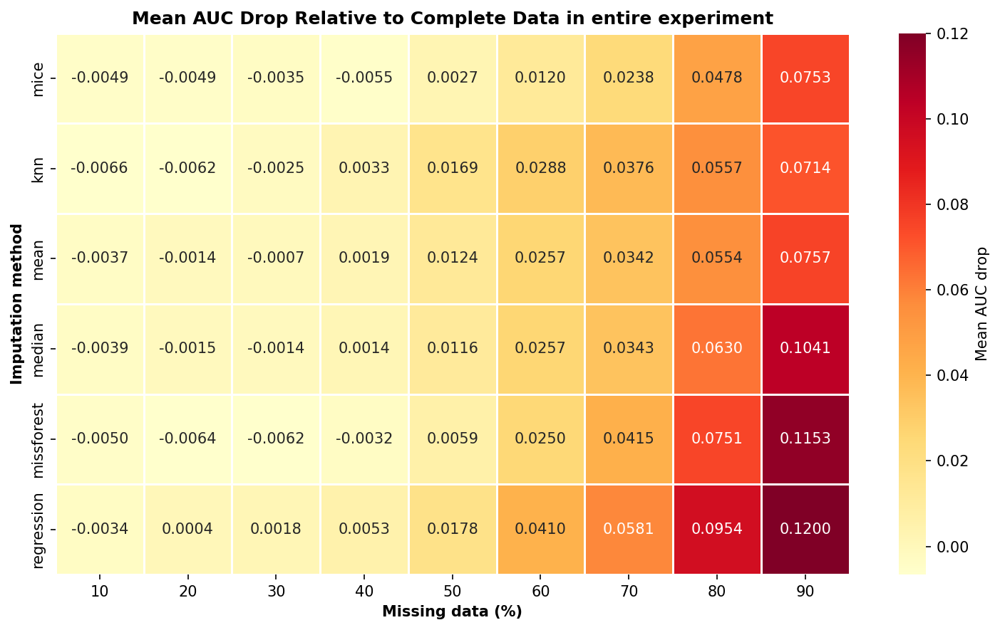

In [7]:
auc_processed_dfs = []

for dataset_name, df in disease_dataframes.items():
    baseline = df[df['missing_pct'] == 0][['classification', 'auc']].copy()
    baseline.rename(columns={'auc': 'baseline_auc'}, inplace=True)
    
    df_merged = df.merge(baseline, on='classification', how='left')
    df_merged['auc_drop'] = df_merged['baseline_auc'] - df_merged['auc']
    df_merged['dataset'] = dataset_name
    
    auc_processed_dfs.append(df_merged)

full_auc_df = pd.concat(auc_processed_dfs, ignore_index=True)

df_auc_imputed_only = full_auc_df[full_auc_df['missing_pct'] > 0]

pivot_mpc = df_auc_imputed_only.pivot_table(
    values='auc_drop', 
    index='imputation', 
    columns='missing_pct', 
    aggfunc='mean'
)
pivot_mpc = pivot_mpc.loc[pivot_mpc.mean(axis=1).sort_values().index]

plt.figure(figsize=(10, 6), dpi=150)
sns.heatmap(
    pivot_mpc, 
    annot=True, 
    fmt=".4f", 
    cmap="YlOrRd",
    cbar_kws={'label': 'Mean AUC drop'},
    linewidths=0.5
)

plt.title(
    'Mean AUC Drop Relative to Complete Data in entire experiment', 
    fontweight='bold'
    )
plt.xlabel('Missing data (%)', fontweight='bold')
plt.ylabel('Imputation method', fontweight='bold')
plt.tight_layout()

out_dir_path = PLOT_PATH
out_dir_path.mkdir(parents=True, exist_ok=True)
out_file_path = out_dir_path / f"AUCdrop_ImpMethod_MissPrct_All.png"
plt.savefig(out_file_path)
            
plt.show()

***Imputation method - Classifier - AUC drop for MAR***

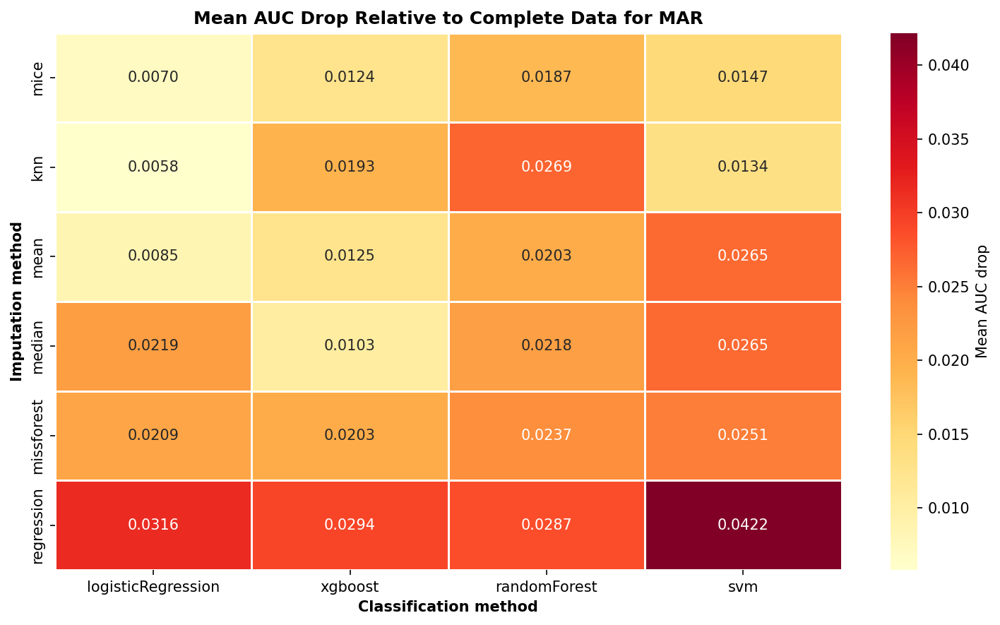

In [8]:
pivot_clf = df_auc_imputed_only_mar.pivot_table(
    values='auc_drop', 
    index='imputation', 
    columns='classification', 
    aggfunc='mean'
)
sorted_rows = pivot_clf.mean(axis=1).sort_values().index
sorted_columns = pivot_clf.mean(axis=0).sort_values().index

pivot_clf = pivot_clf.loc[sorted_rows, sorted_columns]

plt.figure(figsize=(10, 6), dpi=150)
sns.heatmap(
    pivot_clf, 
    annot=True, 
    fmt=".4f", 
    cmap="YlOrRd",
    cbar_kws={'label': 'Mean AUC drop'},
    linewidths=0.5
)

plt.title(
    'Mean AUC Drop Relative to Complete Data for MAR', 
    fontweight='bold'
    )
plt.xlabel('Classification method', fontweight='bold')
plt.ylabel('Imputation method', fontweight='bold')
plt.tight_layout()

out_dir_path = PLOT_PATH
out_dir_path.mkdir(parents=True, exist_ok=True)
out_file_path = out_dir_path / f"AUCdrop_ImpMethod_ClassMethod_MAR.png"
plt.savefig(out_file_path)
          
plt.show()


***Imputation method - Classifier - AUC drop for MCAR***

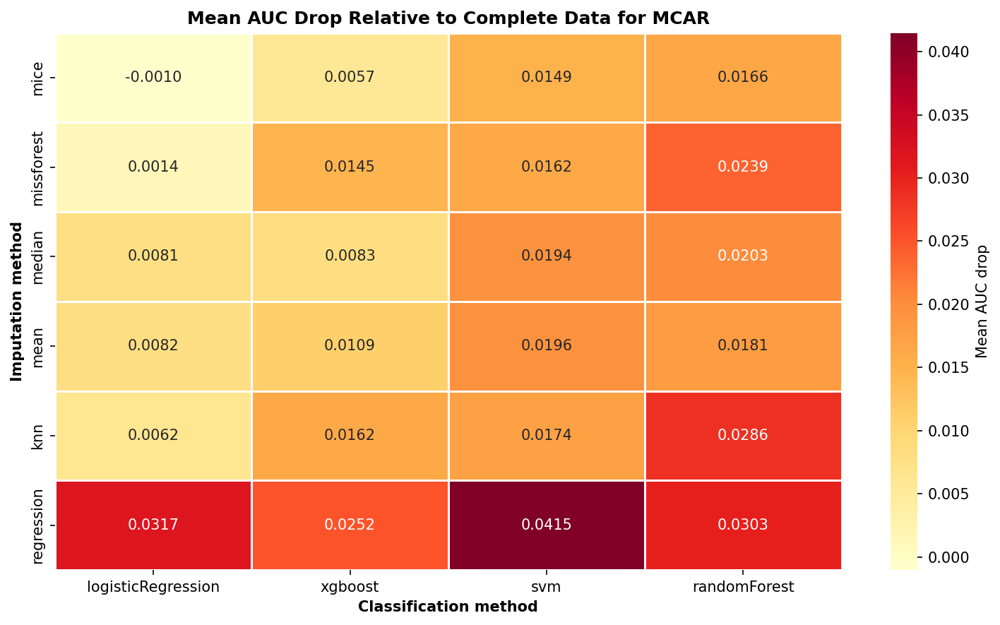

In [9]:
pivot_clf = df_auc_imputed_only_mcar.pivot_table(
    values='auc_drop', 
    index='imputation', 
    columns='classification', 
    aggfunc='mean'
)
sorted_rows = pivot_clf.mean(axis=1).sort_values().index
sorted_columns = pivot_clf.mean(axis=0).sort_values().index

pivot_clf = pivot_clf.loc[sorted_rows, sorted_columns]

plt.figure(figsize=(10, 6), dpi=150)
sns.heatmap(
    pivot_clf, 
    annot=True, 
    fmt=".4f", 
    cmap="YlOrRd",
    cbar_kws={'label': 'Mean AUC drop'},
    linewidths=0.5
)

plt.title(
    'Mean AUC Drop Relative to Complete Data for MCAR', 
    fontweight='bold'
    )
plt.xlabel('Classification method', fontweight='bold')
plt.ylabel('Imputation method', fontweight='bold')
plt.tight_layout()

out_dir_path = PLOT_PATH
out_dir_path.mkdir(parents=True, exist_ok=True)
out_file_path = out_dir_path / f"AUCdrop_ImpMethod_ClassMethod_MCAR.png"
plt.savefig(out_file_path)
          
plt.show()


***Imputation method - Classifier - AUC drop for MNAR***

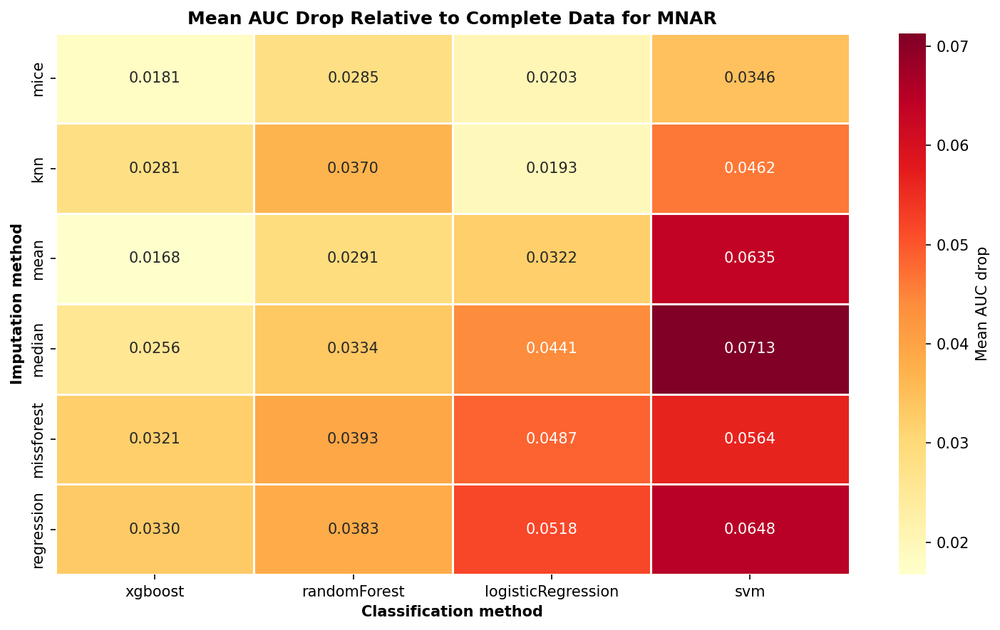

In [10]:
pivot_clf = df_auc_imputed_only_mnar.pivot_table(
    values='auc_drop', 
    index='imputation', 
    columns='classification', 
    aggfunc='mean'
)
sorted_rows = pivot_clf.mean(axis=1).sort_values().index
sorted_columns = pivot_clf.mean(axis=0).sort_values().index

pivot_clf = pivot_clf.loc[sorted_rows, sorted_columns]

plt.figure(figsize=(10, 6), dpi=150)
sns.heatmap(
    pivot_clf, 
    annot=True, 
    fmt=".4f", 
    cmap="YlOrRd",
    cbar_kws={'label': 'Mean AUC drop'},
    linewidths=0.5
)

plt.title(
    'Mean AUC Drop Relative to Complete Data for MNAR', 
    fontweight='bold'
    )
plt.xlabel('Classification method', fontweight='bold')
plt.ylabel('Imputation method', fontweight='bold')
plt.tight_layout()

out_dir_path = PLOT_PATH
out_dir_path.mkdir(parents=True, exist_ok=True)
out_file_path = out_dir_path / f"AUCdrop_ImpMethod_ClassMethod_MNAR.png"
plt.savefig(out_file_path)
          
plt.show()


***Imputation method - Classifier - AUC drop for entire experiment***

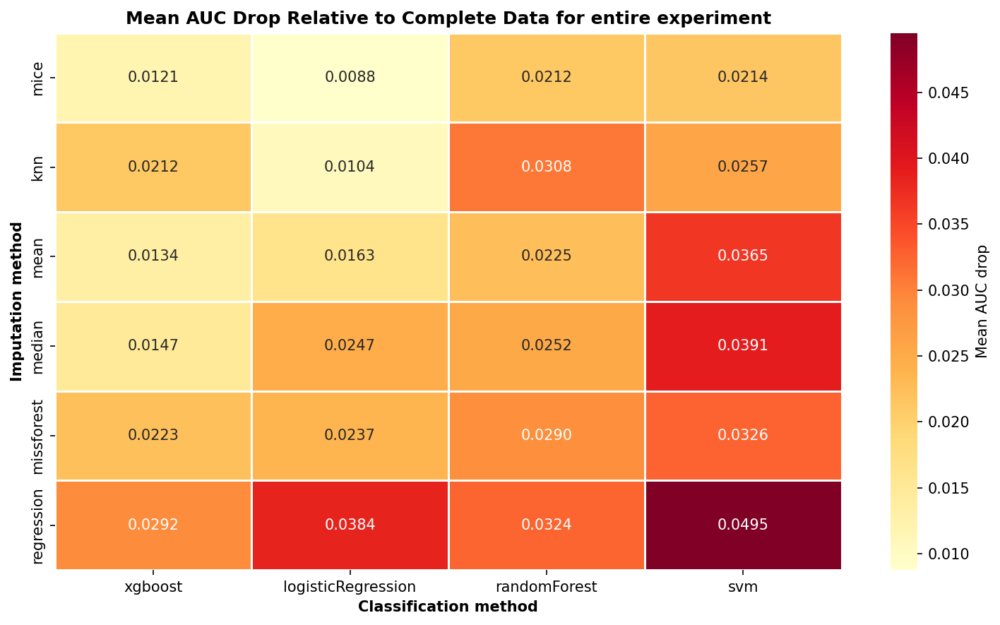

In [11]:
pivot_clf = df_auc_imputed_only.pivot_table(
    values='auc_drop', 
    index='imputation', 
    columns='classification', 
    aggfunc='mean'
)
sorted_rows = pivot_clf.mean(axis=1).sort_values().index
sorted_columns = pivot_clf.mean(axis=0).sort_values().index

pivot_clf = pivot_clf.loc[sorted_rows, sorted_columns]

plt.figure(figsize=(10, 6), dpi=150)
sns.heatmap(
    pivot_clf, 
    annot=True, 
    fmt=".4f", 
    cmap="YlOrRd",
    cbar_kws={'label': 'Mean AUC drop'},
    linewidths=0.5
)

plt.title(
    'Mean AUC Drop Relative to Complete Data for entire experiment', 
    fontweight='bold'
    )
plt.xlabel('Classification method', fontweight='bold')
plt.ylabel('Imputation method', fontweight='bold')
plt.tight_layout()

out_dir_path = PLOT_PATH
out_dir_path.mkdir(parents=True, exist_ok=True)
out_file_path = out_dir_path / f"AUCdrop_ImpMethod_ClassMethod_All.png"
plt.savefig(out_file_path)
          
plt.show()


***Imputation times***

In [ ]:
imputation_results = []

for i in range(SAMPLE_NUM):
    sample_folder = IMPUTATION_PATH / f"sample{i+1}"
    for file_path in sorted(sample_folder.glob("*.txt")):
        parsed = parse_imputation_report_filename(file_path.name)
        if parsed:
            cells_total, time_total, time_per_cell = extract_metrics_from_imputation_report(file_path)
            parsed['cells_total'] = cells_total
            parsed['time_total'] = time_total
            parsed['time_per_cell'] = time_per_cell
            parsed['sample'] = i + 1
            imputation_results.append(parsed)

df_imputation_times = pd.DataFrame(imputation_results)

print(df_imputation_times)

            disease missing_type  missing_pct  imputation  cells_total  \
0     breast_cancer          mar           10         knn        491.0   
1     breast_cancer          mar           10        mean        491.0   
2     breast_cancer          mar           10      median        491.0   
3     breast_cancer          mar           10        mice        491.0   
4     breast_cancer          mar           10  missforest        491.0   
...             ...          ...          ...         ...          ...   
4855        obesity         mnar           90        mean      24307.0   
4856        obesity         mnar           90      median      24307.0   
4857        obesity         mnar           90        mice      24307.0   
4858        obesity         mnar           90  missforest      24307.0   
4859        obesity         mnar           90  regression      24307.0   

      time_total  time_per_cell  sample  
0       0.028023   5.702590e-06       1  
1       0.007008   1.426096

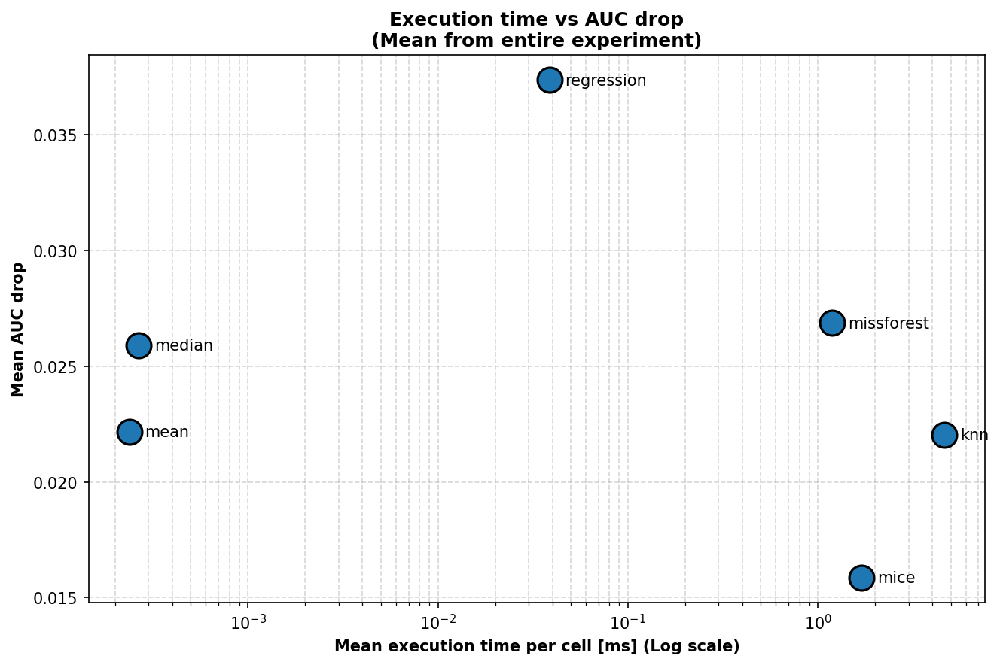

In [33]:
df_auc_summary = df_auc_imputed_only.groupby('imputation', as_index=False).agg(
    mean_auc_drop=('auc_drop', 'mean')
)

df_time_summary = df_imputation_times.groupby('imputation', as_index=False).agg(
    cells_total=('cells_total', 'sum'),
    time_total=('time_total', 'sum')
)

df_time_summary['average_time_per_cell_ms'] = (
    (df_time_summary['time_total'] / df_time_summary['cells_total']) * 1000
)

df_time_summary = df_time_summary.drop(columns=['cells_total']) # , 'time_total'

auc_time_df = pd.merge(df_auc_summary, df_time_summary, on='imputation')

plt.figure(figsize=(9, 6), dpi=150)
ax = sns.scatterplot(
    data=auc_time_df,
    x='average_time_per_cell_ms',
    y='mean_auc_drop',
    s=250,
    color='#1f77b4',
    edgecolor='black',
    linewidth=1.5,
    zorder=3
)

for i in range(len(auc_time_df)):
    row = auc_time_df.iloc[i]
    plt.annotate(
        row['imputation'], 
        (row['average_time_per_cell_ms'], row['mean_auc_drop']),
        xytext=(10, -3), 
        textcoords='offset points',
    )

plt.xscale('log')

plt.title(
    'Execution time vs AUC drop\n(Mean from entire experiment)', 
    fontweight='bold'
    )
plt.xlabel('Mean execution time per cell [ms] (Log scale)', fontweight='bold')
plt.ylabel('Mean AUC drop', fontweight='bold')

plt.grid(True, which="both", ls="--", alpha=0.5, zorder=1)
plt.tight_layout()

out_dir_path = PLOT_PATH
out_dir_path.mkdir(parents=True, exist_ok=True)
out_file_path = out_dir_path / f"ImpMethod_AUCdrop_Time.png"
plt.savefig(out_file_path)
          
plt.show()

In [32]:
auc_time_df.sort_values('average_time_per_cell_ms')

,imputation,mean_auc_drop,time_total,average_time_per_cell_ms
1,mean,0.022166,30.729419,0.000237
2,median,0.025920,34.399298,0.000266
5,regression,0.037376,4987.148585,0.038590
4,missforest,0.026876,153842.138155,1.190422
3,mice,0.015866,219347.752549,1.697301
0,knn,0.022044,599354.020585,4.637768
